# 05 — Training ECGTransForm (aman, reproducible, resumable)

Notebook ini **melatih** ECGTransForm (Biomed. Signal Process. Control, 2024; DOI 10.1016/j.bspc.2023.105714; repo `emadeldeen24/ECGTransForm`) pada MIT-BIH proyek dan membandingkannya dengan baseline ResNet18 + GAF. Ini **bukan** audit; hasil `04_audit_ecgtransform.ipynb` (FEASIBLE WITH ADAPTATION, commit `2f5c28c`) dipakai sebagai dasar.

## Protokol (ditetapkan SEBELUM training)

| Aspek | Keputusan |
|---|---|
| Train | **train mentah 87.554** (tanpa SMOTE). Bila tidak ditemukan secara eksplisit, notebook **berhenti** (lihat flag `ACCEPT_INFERRED_RAW_SLICE`) |
| Validation | 20% stratified dari train mentah (`random_state=42`) → 80% training / 20% validation |
| Test | `X_test.npy` / `y_test.npy` (21.892) **tidak disentuh** sampai sel evaluasi akhir; dievaluasi **satu kali** |
| Loss | `CrossEntropyLoss(weight=CAL)`; bobot CAL dihitung dengan `get_class_weight` repo dari label **training split** |
| Optimizer / hparams | Dibaca dari `configs/hparams.py` repo (60 epoch, batch 128, lr 1e-3, weight decay 1e-4) + Adam betas (0,9; 0,99) seperti `trainer.py`. Tidak ada tuning |
| Seleksi checkpoint | **Validation Macro F1** tertinggi (seri → epoch lebih awal). Bukan test |
| Model | `ecgTransForm` asli, tidak dimodifikasi; input 187 titik utuh `(B,1,187)` |

## Cara menjalankan
1. Jalankan sel 1–6 (setup, repo, data, split, model). Semua flag di bawah masih `False`.
2. Setel `RUN_SMOKE_TEST = True`, jalankan sel smoke test. Harus **PASS**.
3. Setel `RUN_FULL_TRAINING = True` **secara manual**; jalankan sel training. Jika Colab terputus: setel `RESUME = True` dan jalankan ulang sel 1–6 lalu sel training.
4. Setelah training selesai: `RUN_FINAL_EVALUATION = True` → evaluasi test satu kali.
5. Sel terakhir menampilkan ringkasan dan membaca hasil dari file yang tersimpan.

In [34]:
# ===== 1. Imports, FLAG, dan konstanta =====
import os, sys
sys.dont_write_bytecode = True                       # jangan menulis __pycache__ ke dalam repo
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # untuk determinisme CUDA; harus sebelum CUDA dipakai

import glob, hashlib, json, logging, platform, random, re, shutil, subprocess, time
from datetime import datetime

import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

# ---------------- FLAG (semua default aman: tidak ada training otomatis) ----------------
RUN_SMOKE_TEST = False             # True -> jalankan smoke test (subset kecil dari train/val; test TIDAK dipakai)
RUN_FULL_TRAINING = False          # True -> training penuh (aktifkan manual setelah smoke test PASS)
RUN_FINAL_EVALUATION = True       # True -> evaluasi test SATU kali (hanya setelah training selesai)
RESUME = True                     # True -> lanjutkan dari checkpoint epoch terakhir di Drive
ACCEPT_INFERRED_RAW_SLICE = False  # True HANYA jika Anda sadar train mentah = X_train_smote[:87554] adalah INFERENCE (bukan bukti)

# ---------------- Konstanta proyek ----------------
SEED = 42
VAL_FRACTION = 0.20
N_TRAIN_RAW, N_TEST, SEQ_LEN, N_CLASSES = 87554, 21892, 187, 5
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
EXPECTED_TRAIN_RAW = {0: 72471, 1: 2223, 2: 5788, 3: 641, 4: 6431}
EXPECTED_TEST = {0: 18118, 1: 556, 2: 1448, 3: 162, 4: 1608}
BASELINE = {"accuracy": 98.86, "macro_precision": 95.23, "macro_recall": 91.97, "macro_f1": 93.53}   # ResNet18 + GAF (Week 1)

PAPER = "ECGTransForm: Empowering adaptive ECG arrhythmia classification framework with bidirectional transformer"
DOI = "10.1016/j.bspc.2023.105714"
REPO_URL = "https://github.com/emadeldeen24/ECGTransForm.git"
REPO_COMMIT = "2f5c28c088ff65681649e3c267c0894336ec412a"      # commit yang diaudit di notebook 04
AUDIT_N_PARAMS = 637689                                         # dari ecgtransform_audit.json
KEEP_LAST_EPOCH_CKPTS = 3          # hanya N checkpoint epoch terakhir yang disimpan (hemat Drive); best selalu disimpan

In [35]:
# ===== 2. Drive, path, seed, environment, logging =====
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE_DIR = os.environ.get("ECG_BASE_DIR", "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion")
if not os.path.isdir(BASE_DIR):
    raise FileNotFoundError(f"BASE_DIR tidak ditemukan: {BASE_DIR}. Notebook berhenti agar tidak membuat struktur proyek baru secara diam-diam.")

DATA_DIR = os.path.join(BASE_DIR, "data")
FEATURES_DIR = os.path.join(BASE_DIR, "features")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")
FIG_DIR = os.path.join(BASE_DIR, "outputs", "figures")
LOG_DIR = os.path.join(BASE_DIR, "logs")
for d in (CKPT_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

WORK_DIR = os.environ.get("ECG_WORK_DIR", "/content" if IN_COLAB else "/tmp")
REPO_DIR = os.path.join(WORK_DIR, "ECGTransForm")               # di luar Drive

HISTORY_CSV = os.path.join(RESULTS_DIR, "week_ecgtransform_history.csv")
BEST_JSON = os.path.join(RESULTS_DIR, "ecgtransform_best_checkpoint.json")
TEST_METRICS_CSV = os.path.join(RESULTS_DIR, "ecgtransform_test_metrics.csv")
TEST_REPORT_CSV = os.path.join(RESULTS_DIR, "ecgtransform_classification_report.csv")
TEST_CM_CSV = os.path.join(RESULTS_DIR, "ecgtransform_confusion_matrix.csv")
COMPARISON_CSV = os.path.join(RESULTS_DIR, "ecgtransform_vs_baseline.csv")
EXP_LOG_PATH = os.path.join(RESULTS_DIR, "ecgtransform_experiment_log.json")
SPLIT_PATH = os.path.join(RESULTS_DIR, "ecgtransform_split_indices.npz")
BEST_CKPT = os.path.join(CKPT_DIR, "ecgtransform_best_val_f1.pt")
TRAIN_LOG_TXT = os.path.join(LOG_DIR, "ecgtransform_train.log")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)    # beberapa op CUDA tetap non-deterministik (hanya warning)


set_seed(SEED)

ENV = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "device": str(DEVICE),
}

logger = logging.getLogger("ecgtransform")
logger.setLevel(logging.INFO)
if not logger.handlers:                                           # hindari handler ganda bila sel dijalankan ulang
    fh = logging.FileHandler(TRAIN_LOG_TXT, mode="a", encoding="utf-8")
    fh.setFormatter(logging.Formatter("%(asctime)s | %(message)s"))
    logger.addHandler(fh)


def log_update(**kw):
    """Gabungkan kw ke experiment log JSON (atomic write)."""
    cur = {}
    if os.path.exists(EXP_LOG_PATH):
        with open(EXP_LOG_PATH, encoding="utf-8") as f:
            cur = json.load(f)
    cur.update(kw)
    tmp = EXP_LOG_PATH + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(cur, f, indent=2, default=str)
    os.replace(tmp, EXP_LOG_PATH)
    return cur


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def dist(y):
    u, c = np.unique(np.asarray(y).astype(np.int64), return_counts=True)
    return {int(k): int(v) for k, v in zip(u, c)}


_existing = json.load(open(EXP_LOG_PATH, encoding="utf-8")) if os.path.exists(EXP_LOG_PATH) else {}
log_update(
    paper=PAPER, doi=DOI, repository=REPO_URL, seed=SEED, **ENV,
    start_time=_existing.get("start_time", datetime.now().isoformat(timespec="seconds")),
    status=_existing.get("status", "INITIALIZED"),
)
print("IN_COLAB :", IN_COLAB)
print("BASE_DIR :", BASE_DIR)
print("ENV      :", ENV)
print("Flags    :", dict(RUN_SMOKE_TEST=RUN_SMOKE_TEST, RUN_FULL_TRAINING=RUN_FULL_TRAINING,
                         RUN_FINAL_EVALUATION=RUN_FINAL_EVALUATION, RESUME=RESUME,
                         ACCEPT_INFERRED_RAW_SLICE=ACCEPT_INFERRED_RAW_SLICE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IN_COLAB : True
BASE_DIR : /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion
ENV      : {'python_version': '3.13.16', 'torch_version': '2.14.1+cu130', 'numpy_version': '2.4.6', 'sklearn_version': '1.6.1', 'cuda_version': '13.0', 'gpu_name': 'Tesla T4', 'device': 'cuda'}
Flags    : {'RUN_SMOKE_TEST': False, 'RUN_FULL_TRAINING': False, 'RUN_FINAL_EVALUATION': True, 'RESUME': True, 'ACCEPT_INFERRED_RAW_SLICE': False}


In [36]:
# ===== 3. Repository resmi ECGTransForm (commit tetap, tidak dimodifikasi) =====
if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(["git", "clone", "--quiet", REPO_URL, REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "checkout", "--quiet", REPO_COMMIT], check=True)

HEAD = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
GIT_DIRTY = subprocess.run(["git", "-C", REPO_DIR, "status", "--porcelain"], capture_output=True, text=True, check=True).stdout.strip()
assert HEAD == REPO_COMMIT, f"HEAD {HEAD} != commit yang diaudit {REPO_COMMIT}"
assert GIT_DIRTY == "", f"Repo tidak bersih (ada modifikasi): {GIT_DIRTY}"
print("Repo   :", REPO_URL)
print("Commit :", HEAD, "(git rev-parse HEAD)")

sys.path.insert(0, REPO_DIR)
from configs.data_configs import mit                                   # noqa: E402  kode asli repo
from configs.hparams import supervised                                 # noqa: E402
from dataloader import Load_Dataset, get_class_weight                  # noqa: E402
from models import ecgTransForm                                        # noqa: E402

CFG = mit()
HP = supervised().train_params
print("\nconfig `mit`         :", vars(CFG))
print("hparams `supervised` :", HP)
assert CFG.num_classes == N_CLASSES and CFG.class_names == CLASS_NAMES and CFG.input_channels == 1


def read_repo(rel):
    with open(os.path.join(REPO_DIR, rel), newline=None, encoding="utf-8") as f:
        return f.read()


# ---- Tampilkan trainer.py & main.py APA ADANYA (agar loop training di bawah bisa dicocokkan dengan sumber resmi)
for rel in ("trainer.py", "main.py"):
    print("=" * 100, f"\n{rel}\n", "=" * 100, sep="")
    for i, line in enumerate(read_repo(rel).splitlines(), 1):
        print(f"{i:4d}  {line}")

# ---- Guard: loop training notebook ini mereplikasi Adam(betas 0,9/0,99) + CrossEntropyLoss(weight=CAL),
#      TANPA scheduler / gradient clipping / warmup / AMP. Jika repo ternyata memakainya, BERHENTI (jangan menebak).
trainer_src = read_repo("trainer.py")
REQUIRED = {
    "Adam betas=(0.9, 0.99)": r"betas\s*=\s*\(\s*0\.9\s*,\s*0\.99\s*\)",
    "lr dari hparams['learning_rate']": r"learning_rate",
    "weight_decay dari hparams": r"weight_decay",
    "CrossEntropyLoss(weight=...)": r"CrossEntropyLoss\(\s*weight",
}
missing = [k for k, p in REQUIRED.items() if not re.search(p, trainer_src)]
FORBIDDEN = r"scheduler|clip_grad|warmup|lr_decay|StepLR|CosineAnneal|autocast|GradScaler|early_stop"
hits = [(rel, i, l.strip()) for rel in ("trainer.py", "main.py", "models.py", "utils.py") if os.path.exists(os.path.join(REPO_DIR, rel))
        for i, l in enumerate(read_repo(rel).splitlines(), 1) if re.search(FORBIDDEN, l, re.I)]
print("\nGuard trainer.py -> kebutuhan yang tidak ditemukan :", missing or "tidak ada")
print("Guard repo       -> scheduler/clip/warmup/AMP/early-stop :", hits or "tidak ada")
if missing or hits:
    raise RuntimeError("Loop training di notebook ini tidak lagi sama dengan trainer.py resmi. "
                       "Baca keluaran trainer.py di atas dan sesuaikan loop secara sadar sebelum melanjutkan.")

TRAINING_CONFIG = {
    "optimizer": "Adam", "learning_rate": HP["learning_rate"], "weight_decay": HP["weight_decay"], "betas": [0.9, 0.99],
    "batch_size": HP["batch_size"], "num_epochs": HP["num_epochs"], "scheduler": None, "gradient_clipping": None,
    "warmup": None, "early_stopping": None, "mixed_precision": False,
    "loss": "CrossEntropyLoss(weight=CAL via repo get_class_weight pada label training split)",
    "dropout_config_repo": CFG.dropout, "sequence_len_config(unused_by_code)": CFG.sequence_len, "input_len_used": SEQ_LEN,
    "source": "configs/hparams.py + trainer.py @ " + HEAD,
}
NUM_EPOCHS, BATCH_SIZE = HP["num_epochs"], HP["batch_size"]
log_update(git_commit=HEAD, training_config=TRAINING_CONFIG)

Repo   : https://github.com/emadeldeen24/ECGTransForm.git
Commit : 2f5c28c088ff65681649e3c267c0894336ec412a (git rev-parse HEAD)

config `mit`         : {'num_classes': 5, 'class_names': ['N', 'S', 'V', 'F', 'Q'], 'sequence_len': 186, 'input_channels': 1, 'kernel_size': 8, 'stride': 1, 'dropout': 0.2, 'mid_channels': 32, 'final_out_channels': 128, 'trans_dim': 25, 'num_heads': 5}
hparams `supervised` : {'num_epochs': 60, 'batch_size': 128, 'weight_decay': 0.0001, 'learning_rate': 0.001, 'feature_dim': 128}
trainer.py
   1  import torch
   2  import torch.nn.functional as F
   3  import datetime
   4  import os
   5  import collections
   6  import numpy as np
   7  
   8  import warnings
   9  import sklearn.exceptions
  10  warnings.filterwarnings("ignore", category=sklearn.exceptions.UndefinedMetricWarning)
  11  warnings.simplefilter(action='ignore', category=FutureWarning)
  12  
  13  from models import ecgTransForm
  14  from dataloader import data_generator
  15  from configs.da

{'paper': 'ECGTransForm: Empowering adaptive ECG arrhythmia classification framework with bidirectional transformer',
 'doi': '10.1016/j.bspc.2023.105714',
 'repository': 'https://github.com/emadeldeen24/ECGTransForm.git',
 'seed': 42,
 'python_version': '3.13.16',
 'torch_version': '2.14.1+cu130',
 'numpy_version': '2.4.6',
 'sklearn_version': '1.6.1',
 'cuda_version': '13.0',
 'gpu_name': 'Tesla T4',
 'device': 'cuda',
 'start_time': '2026-11-14T11:12:51',
 'status': 'TRAINING_COMPLETE',
 'git_commit': '2f5c28c088ff65681649e3c267c0894336ec412a',
 'training_config': {'optimizer': 'Adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0001,
  'betas': [0.9, 0.99],
  'batch_size': 128,
  'num_epochs': 60,
  'scheduler': None,
  'gradient_clipping': None,
  'warmup': None,
  'early_stopping': None,
  'mixed_precision': False,
  'loss': 'CrossEntropyLoss(weight=CAL via repo get_class_weight pada label training split)',
  'dropout_config_repo': 0.2,
  'sequence_len_config(unused_by_code)': 

In [37]:
# ===== 4. Dataset: inventaris file, cari TRAIN MENTAH secara eksplisit, test set =====
SEARCH_DIRS = [d for d in (DATA_DIR, FEATURES_DIR) if os.path.isdir(d)]
inventory = []
for d in SEARCH_DIRS:
    for root, _, files in os.walk(d):
        for f in sorted(files):
            if f.lower().endswith((".npy", ".npz", ".csv", ".pt", ".h5", ".hdf5")):
                p = os.path.join(root, f)
                inventory.append({"file": os.path.relpath(p, BASE_DIR), "MB": round(os.path.getsize(p) / 1e6, 2)})
print("File data yang ditemukan di data/ dan features/:")
display(pd.DataFrame(inventory) if inventory else pd.DataFrame({"file": ["(kosong)"]}))

TRAIN_FILES = {n: os.path.join(FEATURES_DIR, n) for n in ("X_train_smote.npy", "y_train_smote.npy", "X_test.npy", "y_test.npy")}
miss = [n for n, p in TRAIN_FILES.items() if not os.path.exists(p)]
if miss:
    raise FileNotFoundError(f"Artifact proyek tidak ditemukan di {FEATURES_DIR}: {miss}")

# ---- Cari train mentah EKSPLISIT: (a) mitbih_train.csv, atau (b) .npy bernama '*train*' (bukan smote) dengan 87.554 baris
raw_candidates_x, raw_candidates_y, raw_csv = [], [], None
for d in SEARCH_DIRS + [BASE_DIR]:
    c = os.path.join(d, "mitbih_train.csv")
    if os.path.exists(c):
        raw_csv = c
for item in inventory:
    p = os.path.join(BASE_DIR, item["file"])
    name = os.path.basename(p).lower()
    if p.endswith(".npy") and "train" in name and "smote" not in name:
        a = np.load(p, mmap_mode="r")
        if a.ndim == 2 and a.shape == (N_TRAIN_RAW, SEQ_LEN):
            raw_candidates_x.append(p)
        elif a.ndim == 1 and a.shape[0] == N_TRAIN_RAW:
            raw_candidates_y.append(p)

TRAIN_SOURCE, TRAIN_SOURCE_STATUS = None, None
if raw_csv:
    df = pd.read_csv(raw_csv, header=None).values
    assert df.shape == (N_TRAIN_RAW, SEQ_LEN + 1), f"Bentuk CSV tidak sesuai: {df.shape}"
    X_raw, y_raw = df[:, :SEQ_LEN].astype(np.float32), df[:, SEQ_LEN].astype(np.int64)
    TRAIN_SOURCE, TRAIN_SOURCE_STATUS = raw_csv, "EXPLICIT (mitbih_train.csv)"
elif len(raw_candidates_x) == 1 and len(raw_candidates_y) == 1:
    X_raw = np.load(raw_candidates_x[0]).astype(np.float32)
    y_raw = np.load(raw_candidates_y[0]).astype(np.int64)
    TRAIN_SOURCE, TRAIN_SOURCE_STATUS = f"{raw_candidates_x[0]} + {raw_candidates_y[0]}", "EXPLICIT (file .npy train mentah)"
elif raw_candidates_x or raw_candidates_y:
    raise RuntimeError(f"Kandidat train mentah ambigu: X={raw_candidates_x}, y={raw_candidates_y}. Tentukan satu secara manual.")
else:
    # ---- Tidak ada train mentah eksplisit. Jangan diam-diam memakai data yang statusnya tidak pasti.
    X_sm = np.load(TRAIN_FILES["X_train_smote.npy"], mmap_mode="r")
    y_sm = np.load(TRAIN_FILES["y_train_smote.npy"])
    print("\n" + "!" * 100)
    print("TRAIN MENTAH 87.554 TIDAK DITEMUKAN SECARA EKSPLISIT.")
    print(f"  Ditemukan: X_train_smote {X_sm.shape}, y_train_smote {y_sm.shape} (hasil SMOTE), tanpa mitbih_train.csv / train mentah terpisah.")
    print(f"  Slice X_train_smote[:{N_TRAIN_RAW}] berdistribusi {dist(y_sm[:N_TRAIN_RAW])}; sisa baris tidak memuat kelas 0: {0 not in dist(y_sm[N_TRAIN_RAW:])}.")
    print("  Itu hanya INFERENCE (distribusi = Table 1 paper), BUKAN bukti identik dengan train mentah asli.")
    print("!" * 100)
    if not ACCEPT_INFERRED_RAW_SLICE:
        raise RuntimeError(
            "Dihentikan: train mentah tidak tersedia secara eksplisit. Pilihan: (1) letakkan mitbih_train.csv atau X/y train mentah "
            "(87.554 baris) di data/ atau features/, lalu jalankan ulang; atau (2) setel ACCEPT_INFERRED_RAW_SLICE = True "
            "dengan sadar bahwa status data adalah INFERENCE; keputusan ini akan dicatat di experiment log.")
    X_raw = np.array(X_sm[:N_TRAIN_RAW], dtype=np.float32)
    y_raw = y_sm[:N_TRAIN_RAW].astype(np.int64)
    TRAIN_SOURCE = f"{TRAIN_FILES['X_train_smote.npy']}[:{N_TRAIN_RAW}]"
    TRAIN_SOURCE_STATUS = "INFERENCE (slice X_train_smote[:87554]; diterima manual via ACCEPT_INFERRED_RAW_SLICE=True)"
    assert 0 not in dist(y_sm[N_TRAIN_RAW:]), "Sisa baris SMOTE ternyata memuat kelas 0: asumsi slice tidak berlaku."

assert X_raw.shape == (N_TRAIN_RAW, SEQ_LEN) and y_raw.shape == (N_TRAIN_RAW,)
assert dist(y_raw) == EXPECTED_TRAIN_RAW, f"Distribusi train mentah {dist(y_raw)} != Table 1 {EXPECTED_TRAIN_RAW}"
print("\nTRAIN source :", TRAIN_SOURCE)
print("TRAIN status :", TRAIN_SOURCE_STATUS)

# ---- Test set: dimuat read-only HANYA untuk assert/integritas. Tidak masuk DataLoader apa pun sampai evaluasi akhir.
TEST_SHA_BEFORE = {"X": sha256_file(TRAIN_FILES["X_test.npy"]), "y": sha256_file(TRAIN_FILES["y_test.npy"])}
X_test = np.load(TRAIN_FILES["X_test.npy"]); y_test = np.load(TRAIN_FILES["y_test.npy"])
X_test.setflags(write=False); y_test.setflags(write=False)
assert len(X_test) == 21892 and len(y_test) == 21892
assert X_test.shape == (N_TEST, SEQ_LEN) and dist(y_test) == EXPECTED_TEST
assert np.isfinite(X_test).all() and np.isfinite(X_raw).all()

# ---- Karakteristik data (dicatat; tidak ada normalisasi tambahan yang dipelajari dari data apa pun)
stat = lambda n, X: {"set": n, "shape": X.shape, "dtype": str(X.dtype), "min": float(X.min()), "max": float(X.max()),
                     "mean": float(X.mean()), "std": float(X.std())}
display(pd.DataFrame([stat("train mentah", X_raw), stat("test", X_test)]))
print("Label: train dtype", y_raw.dtype, "| test dtype", y_test.dtype, "-> keduanya di-cast ke int64 (nilai tidak berubah)")
print("Normalisasi: repo tidak menormalisasi; data sudah di [0,1] (audit) -> TIDAK ada normalisasi tambahan. Channel dim ditambah oleh adapter.")

# ---- Overlap check train vs test (exact duplicate baris). Dilaporkan, bukan di-assert nol: dataset beat mungkin punya duplikat alami.
_h = lambda X: [hashlib.blake2b(np.ascontiguousarray(r).tobytes(), digest_size=16).digest() for r in X]
_train_hash_set = set(_h(X_raw))
OVERLAP_TEST_IN_TRAIN = int(sum(h in _train_hash_set for h in _h(X_test)))
print(f"Overlap exact-duplicate: {OVERLAP_TEST_IN_TRAIN} dari {N_TEST} baris test juga muncul di train mentah "
      f"({100 * OVERLAP_TEST_IN_TRAIN / N_TEST:.3f}%). Informasi saja; test tidak dipakai untuk apa pun selain evaluasi akhir.")
del _train_hash_set

log_update(
    dataset="MIT-BIH heartbeat (Kaggle shayanfazeli/heartbeat), 187 titik/beat",
    train_source=TRAIN_SOURCE, train_source_status=TRAIN_SOURCE_STATUS, smote_used=False,
    dataset_shapes={"X_train_raw": list(X_raw.shape), "X_test": list(X_test.shape)},
    class_distribution={"train_raw": dist(y_raw), "test": dist(y_test)},
    overlap_test_rows_in_train=OVERLAP_TEST_IN_TRAIN,
)

File data yang ditemukan di data/ dan features/:


,file,MB
0,data/mitbih_train.csv,411.50
1,features/X_test.npy,16.38
2,features/X_train_smote.npy,114.05
3,features/mff_features_gaf_recall.npz,357.79
4,features/mff_features_mtf_recall.npz,357.79
5,features/mff_features_rp_recall.npz,357.79
6,features/y_test.npy,0.09
7,features/y_train_smote.npy,1.22



TRAIN source : /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/data/mitbih_train.csv
TRAIN status : EXPLICIT (mitbih_train.csv)


,set,shape,dtype,min,max,mean,std
0,train mentah,"(87554, 187)",float32,0.0,1.0,0.174283,0.226327
1,test,"(21892, 187)",float32,0.0,1.0,0.173479,0.225553


Label: train dtype int64 | test dtype int32 -> keduanya di-cast ke int64 (nilai tidak berubah)
Normalisasi: repo tidak menormalisasi; data sudah di [0,1] (audit) -> TIDAK ada normalisasi tambahan. Channel dim ditambah oleh adapter.
Overlap exact-duplicate: 0 dari 21892 baris test juga muncul di train mentah (0.000%). Informasi saja; test tidak dipakai untuk apa pun selain evaluasi akhir.


{'paper': 'ECGTransForm: Empowering adaptive ECG arrhythmia classification framework with bidirectional transformer',
 'doi': '10.1016/j.bspc.2023.105714',
 'repository': 'https://github.com/emadeldeen24/ECGTransForm.git',
 'seed': 42,
 'python_version': '3.13.16',
 'torch_version': '2.14.1+cu130',
 'numpy_version': '2.4.6',
 'sklearn_version': '1.6.1',
 'cuda_version': '13.0',
 'gpu_name': 'Tesla T4',
 'device': 'cuda',
 'start_time': '2026-11-14T11:12:51',
 'status': 'TRAINING_COMPLETE',
 'git_commit': '2f5c28c088ff65681649e3c267c0894336ec412a',
 'training_config': {'optimizer': 'Adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0001,
  'betas': [0.9, 0.99],
  'batch_size': 128,
  'num_epochs': 60,
  'scheduler': None,
  'gradient_clipping': None,
  'warmup': None,
  'early_stopping': None,
  'mixed_precision': False,
  'loss': 'CrossEntropyLoss(weight=CAL via repo get_class_weight pada label training split)',
  'dropout_config_repo': 0.2,
  'sequence_len_config(unused_by_code)': 

In [38]:
# ===== 5. Validation split (stratified 80/20 dari train mentah), CAL, DataLoader =====
def to_ecgtransform_dict(X, y):
    """Adapter MINIMAL (data format saja): (N,187)->(N,1,187) float32, label int64. Nilai tidak berubah."""
    return {"samples": torch.from_numpy(np.array(X, dtype=np.float32, copy=True)).unsqueeze(1),
            "labels": torch.from_numpy(np.array(y).astype(np.int64))}


train_idx, val_idx = train_test_split(np.arange(N_TRAIN_RAW), test_size=VAL_FRACTION, stratify=y_raw, random_state=SEED)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)
assert len(set(train_idx) & set(val_idx)) == 0 and len(train_idx) + len(val_idx) == N_TRAIN_RAW

if os.path.exists(SPLIT_PATH):                                    # split harus identik antar sesi (resume)
    _s = np.load(SPLIT_PATH)
    assert np.array_equal(_s["train_idx"], train_idx) and np.array_equal(_s["val_idx"], val_idx), \
        "Split tersimpan berbeda dengan split baru: sumber data / seed berubah. Hentikan agar resume tidak tercemar."
else:
    np.savez(SPLIT_PATH, train_idx=train_idx, val_idx=val_idx)
SPLIT_SHA = hashlib.sha256(train_idx.tobytes() + val_idx.tobytes()).hexdigest()

X_tr, y_tr, X_va, y_va = X_raw[train_idx], y_raw[train_idx], X_raw[val_idx], y_raw[val_idx]
print(f"Raw train {N_TRAIN_RAW:,} -> training {len(X_tr):,} | validation {len(X_va):,}")
display(pd.DataFrame({"kelas": CLASS_NAMES, "train_split": [dist(y_tr)[i] for i in range(5)],
                      "val_split": [dist(y_va)[i] for i in range(5)], "test (tidak disentuh)": [EXPECTED_TEST[i] for i in range(5)]}))

# informasi: berapa baris validation yang punya duplikat exact di training split (potensi optimisme validation)
_trs = set(hashlib.blake2b(np.ascontiguousarray(r).tobytes(), digest_size=16).digest() for r in X_tr)
VAL_DUP_IN_TRAIN = int(sum(hashlib.blake2b(np.ascontiguousarray(r).tobytes(), digest_size=16).digest() in _trs for r in X_va))
del _trs
print(f"Informasi: {VAL_DUP_IN_TRAIN} baris validation punya duplikat exact di training split.")

# ---- CAL (Context-Aware Loss weights): fungsi ASLI repo, dari label TRAINING split (seperti data_generator pada train.pt)
cw = get_class_weight({i: int((y_tr == i).sum()) for i in range(N_CLASSES)})
CAL_WEIGHTS = [float(cw[i]) for i in range(N_CLASSES)]
W = torch.tensor(CAL_WEIGHTS, dtype=torch.float32, device=DEVICE)
print("Bobot CAL (N,S,V,F,Q):", np.round(CAL_WEIGHTS, 4))

# ---- Dataset/DataLoader: Load_Dataset ASLI repo. Beda dari data_generator: val drop_last=False (semua sampel validation dihitung).
train_ds = Load_Dataset(to_ecgtransform_dict(X_tr, y_tr))
val_ds = Load_Dataset(to_ecgtransform_dict(X_va, y_va))
_g = torch.Generator()


def make_train_loader(epoch):
    _g.manual_seed(SEED + epoch)                                  # urutan shuffle deterministik per epoch -> resume reproducible
    return DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=0, generator=_g)


val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=0)
_b = next(iter(val_loader))
assert tuple(_b["samples"].shape[1:]) == (1, SEQ_LEN) and _b["samples"].dtype == torch.float32 and _b["labels"].dtype == torch.int64
print("Batch:", tuple(_b["samples"].shape), _b["samples"].dtype, "| labels", _b["labels"].dtype)

print("""
DATA LEAKAGE CHECK
  Raw train (87.554) -> 80% training / 20% validation (stratified, seed 42, dari TRAIN saja)
  Test (21.892)      -> TIDAK dibuat DataLoader, tidak dipakai untuk seleksi epoch/checkpoint/hyperparameter/early stopping;
                        baru dibuka di sel evaluasi akhir (satu kali).
  SMOTE              -> tidak dipakai.
""")
log_update(validation_split={"method": "train_test_split(stratify=y, random_state=42)", "test_size": VAL_FRACTION,
                             "n_train": int(len(X_tr)), "n_val": int(len(X_va)), "split_sha256": SPLIT_SHA,
                             "train_dist": dist(y_tr), "val_dist": dist(y_va), "val_rows_duplicated_in_train": VAL_DUP_IN_TRAIN},
           cal_weights=CAL_WEIGHTS)

Raw train 87,554 -> training 70,043 | validation 17,511


,kelas,train_split,val_split,test (tidak disentuh)
0,N,57977,14494,18118
1,S,1778,445,556
2,V,4630,1158,1448
3,F,513,128,162
4,Q,5145,1286,1608


Informasi: 0 baris validation punya duplikat exact di training split.
Bobot CAL (N,S,V,F,Q): [1.     3.4846 2.5275 4.7275 2.422 ]
Batch: (128, 1, 187) torch.float32 | labels torch.int64

DATA LEAKAGE CHECK
  Raw train (87.554) -> 80% training / 20% validation (stratified, seed 42, dari TRAIN saja)
  Test (21.892)      -> TIDAK dibuat DataLoader, tidak dipakai untuk seleksi epoch/checkpoint/hyperparameter/early stopping;
                        baru dibuka di sel evaluasi akhir (satu kali).
  SMOTE              -> tidak dipakai.



{'paper': 'ECGTransForm: Empowering adaptive ECG arrhythmia classification framework with bidirectional transformer',
 'doi': '10.1016/j.bspc.2023.105714',
 'repository': 'https://github.com/emadeldeen24/ECGTransForm.git',
 'seed': 42,
 'python_version': '3.13.16',
 'torch_version': '2.14.1+cu130',
 'numpy_version': '2.4.6',
 'sklearn_version': '1.6.1',
 'cuda_version': '13.0',
 'gpu_name': 'Tesla T4',
 'device': 'cuda',
 'start_time': '2026-11-14T11:12:51',
 'status': 'TRAINING_COMPLETE',
 'git_commit': '2f5c28c088ff65681649e3c267c0894336ec412a',
 'training_config': {'optimizer': 'Adam',
  'learning_rate': 0.001,
  'weight_decay': 0.0001,
  'betas': [0.9, 0.99],
  'batch_size': 128,
  'num_epochs': 60,
  'scheduler': None,
  'gradient_clipping': None,
  'warmup': None,
  'early_stopping': None,
  'mixed_precision': False,
  'loss': 'CrossEntropyLoss(weight=CAL via repo get_class_weight pada label training split)',
  'dropout_config_repo': 0.2,
  'sequence_len_config(unused_by_code)': 

In [39]:
# ===== 6. Model, metrik, loop train/eval, checkpoint =====
def build_model():
    return ecgTransForm(configs=CFG, hparams=HP).to(DEVICE)       # model ASLI, tidak dimodifikasi


def make_optimizer(model):
    return torch.optim.Adam(model.parameters(), lr=HP["learning_rate"], weight_decay=HP["weight_decay"], betas=(0.9, 0.99))


_m = build_model()
N_PARAMS_TOTAL = sum(p.numel() for p in _m.parameters())
N_PARAMS_TRAINABLE = sum(p.numel() for p in _m.parameters() if p.requires_grad)
N_PARAMS_UNUSED = sum(p.numel() for n, p in _m.named_parameters() if n.startswith("encoder_layer."))
print(f"Parameter total      : {N_PARAMS_TOTAL:,}")
print(f"Parameter trainable  : {N_PARAMS_TRAINABLE:,}  (requires_grad)")
print(f"  di antaranya `encoder_layer.*` tak dipakai langsung (tanpa gradien): {N_PARAMS_UNUSED:,}")
assert N_PARAMS_TOTAL == AUDIT_N_PARAMS, f"Jumlah parameter {N_PARAMS_TOTAL} != audit {AUDIT_N_PARAMS}"
del _m
log_update(n_params_total=N_PARAMS_TOTAL, n_params_trainable=N_PARAMS_TRAINABLE, n_params_unused_encoder_layer=N_PARAMS_UNUSED)


def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASSES)), average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)), "macro_precision": float(p), "macro_recall": float(r), "macro_f1": float(f)}


def train_one_epoch(model, optimizer, loader):
    """Metrik train = metrik berjalan selama epoch (dropout aktif, bobot berubah), bukan evaluasi ulang pasca-epoch."""
    model.train()
    criterion = nn.CrossEntropyLoss(weight=W)
    ys, ps, loss_sum, w_sum = [], [], 0.0, 0.0
    for b in loader:
        x, y = b["samples"].to(DEVICE), b["labels"].to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        if not torch.isfinite(loss):
            raise FloatingPointError("Loss non-finite saat training; hentikan dan periksa.")
        loss.backward()
        optimizer.step()
        ws = W[y].sum().item()
        loss_sum += loss.item() * ws; w_sum += ws                  # rata-rata berbobot yang konsisten dengan CE berbobot
        ys.append(y.cpu().numpy()); ps.append(out.argmax(1).detach().cpu().numpy())
    m = compute_metrics(np.concatenate(ys), np.concatenate(ps)); m["loss"] = loss_sum / w_sum
    return m


@torch.no_grad()
def evaluate(model, loader, return_preds=False):
    model.eval()
    ys, ps, loss_sum, w_sum = [], [], 0.0, 0.0
    for b in loader:
        x, y = b["samples"].to(DEVICE), b["labels"].to(DEVICE)
        out = model(x)
        loss_sum += F.cross_entropy(out, y, weight=W, reduction="sum").item(); w_sum += W[y].sum().item()
        ys.append(y.cpu().numpy()); ps.append(out.argmax(1).cpu().numpy())
    yt, yp = np.concatenate(ys), np.concatenate(ps)
    m = compute_metrics(yt, yp); m["loss"] = loss_sum / w_sum
    return (m, yt, yp) if return_preds else m


# ---------------- checkpoint ----------------
def epoch_ckpt_path(d, e):
    return os.path.join(d, f"ecgtransform_epoch_{e:03d}.pt")


def list_epoch_ckpts(d):
    out = []
    for p in glob.glob(os.path.join(d, "ecgtransform_epoch_*.pt")):
        m = re.search(r"ecgtransform_epoch_(\d+)\.pt$", p)
        if m:
            out.append((int(m.group(1)), p))
    return sorted(out)


def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def restore_rng(s):
    random.setstate(s["python"]); np.random.set_state(s["numpy"]); torch.set_rng_state(s["torch"].cpu())
    if s["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu() for t in s["cuda"]])


FINGERPRINT = {"seed": SEED, "split_sha256": SPLIT_SHA, "repo_commit": HEAD, "num_epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE,
               "learning_rate": HP["learning_rate"], "weight_decay": HP["weight_decay"], "cal_weights": CAL_WEIGHTS,
               "train_source_status": TRAIN_SOURCE_STATUS}


def save_epoch_ckpt(d, epoch, model, optimizer, history, best):
    atomic_save({"epoch": epoch, "model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(),
                 "scheduler_state_dict": None,                      # repo tidak memakai scheduler (di-guard di sel 3)
                 "best_val_macro_f1": best["f1"], "best_epoch": best["epoch"], "history": history,
                 "rng_state": rng_state(), "fingerprint": FINGERPRINT}, epoch_ckpt_path(d, epoch))


def load_ckpt(path, model, optimizer=None, restore_random=True):
    ck = torch.load(path, map_location="cpu", weights_only=False)   # file buatan sendiri (berisi state RNG)
    fp = ck["fingerprint"]
    for k, v in FINGERPRINT.items():
        same = np.allclose(fp[k], v) if k == "cal_weights" else fp[k] == v
        assert same, f"Fingerprint checkpoint beda pada '{k}': {fp[k]} != {v}. Resume ditolak."
    model.load_state_dict(ck["model_state_dict"])
    if optimizer is not None:
        optimizer.load_state_dict(ck["optimizer_state_dict"])
    if restore_random:
        restore_rng(ck["rng_state"])
    return ck


def write_history(history):
    cols = ["epoch", "train_loss", "train_accuracy", "train_macro_precision", "train_macro_recall", "train_macro_f1",
            "val_loss", "val_accuracy", "val_macro_precision", "val_macro_recall", "val_macro_f1", "learning_rate", "epoch_duration_sec"]
    pd.DataFrame(history, columns=cols).to_csv(HISTORY_CSV, index=False)

Parameter total      : 637,689
Parameter trainable  : 637,689  (requires_grad)
  di antaranya `encoder_layer.*` tak dipakai langsung (tanpa gradien): 107,173


/content/ECGTransForm/models.py:41: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=3)


In [40]:
# ===== 7. SMOKE TEST (subset kecil dari train/val; TEST SET TIDAK DIPAKAI; tidak menyentuh checkpoint/history asli) =====
if RUN_SMOKE_TEST:
    SMOKE_DIR = os.path.join(CKPT_DIR, "_smoke_test")
    shutil.rmtree(SMOKE_DIR, ignore_errors=True); os.makedirs(SMOKE_DIR)
    checks = []
    def chk(name, ok, detail=""):
        checks.append({"check": name, "status": "PASS" if ok else "FAIL", "detail": detail}); return ok

    set_seed(SEED)
    rng = np.random.RandomState(SEED)
    pick = lambda y, n: np.concatenate([rng.choice(np.where(y == c)[0], min(n, int((y == c).sum())), replace=False) for c in range(N_CLASSES)])
    s_tr, s_va = pick(y_tr, 40), pick(y_va, 20)
    SB = 32
    s_train_loader = DataLoader(Subset(train_ds, s_tr.tolist()), batch_size=SB, shuffle=True, drop_last=True, num_workers=0)
    s_val_loader = DataLoader(Subset(val_ds, s_va.tolist()), batch_size=SB, shuffle=False, drop_last=False, num_workers=0)

    # 1) data loader & batch
    b = next(iter(s_train_loader)); x, y = b["samples"].to(DEVICE), b["labels"].to(DEVICE)
    chk("data loader / batch shape", tuple(x.shape) == (SB, 1, SEQ_LEN) and x.dtype == torch.float32 and y.dtype == torch.int64, f"x{tuple(x.shape)} y{tuple(y.shape)}")
    # 2) forward
    model = build_model(); opt = make_optimizer(model); model.train()
    out = model(x)
    chk("forward", tuple(out.shape) == (SB, N_CLASSES) and bool(torch.isfinite(out).all()), f"out{tuple(out.shape)}")
    # 3) loss
    loss = nn.CrossEntropyLoss(weight=W)(out, y)
    chk("loss", bool(torch.isfinite(loss)), f"{loss.item():.4f}")
    # 4) backward + 5) optimizer step
    opt.zero_grad(); loss.backward()
    nograd = [n for n, p in model.named_parameters() if p.grad is None and not n.startswith("encoder_layer.")]
    chk("backward", not nograd and all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None), f"param tanpa grad (di luar encoder_layer): {nograd or 'tidak ada'}")
    before = {n: p.detach().clone() for n, p in model.named_parameters()}
    opt.step()
    changed = sum(not torch.equal(before[n], p.detach()) for n, p in model.named_parameters())
    chk("optimizer step", changed > 0 and all(torch.isfinite(p).all() for p in model.parameters()), f"{changed} parameter berubah")
    # 6) mini-epoch train + validation loop
    tm = train_one_epoch(model, opt, s_train_loader)
    vm = evaluate(model, s_val_loader)
    chk("train epoch + validation loop", all(np.isfinite(list(tm.values()) + list(vm.values()))), f"train_loss={tm['loss']:.4f} val_loss={vm['loss']:.4f} val_f1={vm['macro_f1']:.4f}")
    # 7) checkpoint save -> load (model, optimizer, RNG, history)
    hist = [{"epoch": 1}]; best = {"f1": vm["macro_f1"], "epoch": 1}
    save_epoch_ckpt(SMOKE_DIR, 1, model, opt, hist, best)
    torch.manual_seed(123); _ = torch.rand(1)                       # ubah RNG dulu agar restore terbukti
    model2 = build_model(); opt2 = make_optimizer(model2)
    ck = load_ckpt(epoch_ckpt_path(SMOKE_DIR, 1), model2, opt2)
    model.eval(); model2.eval()
    with torch.no_grad():
        same_out = torch.allclose(model(x), model2(x), atol=0, rtol=0)
    s1, s2 = opt.state_dict()["state"], opt2.state_dict()["state"]
    same_opt = all(torch.equal(s1[k]["exp_avg"], s2[k]["exp_avg"]) for k in s1)
    chk("checkpoint save/load", same_out and same_opt and ck["epoch"] == 1 and ck["history"] == hist, f"output identik={same_out}, optimizer state identik={same_opt}")
    # 8) test set tidak dipakai
    chk("test set tidak dipakai", True, "smoke test hanya memakai subset training/validation")

    shutil.rmtree(SMOKE_DIR, ignore_errors=True)
    smoke_df = pd.DataFrame(checks); display(smoke_df)
    SMOKE_PASS = bool((smoke_df["status"] == "PASS").all())
    log_update(smoke_test={"status": "PASS" if SMOKE_PASS else "FAIL", "time": datetime.now().isoformat(timespec="seconds"), "checks": checks})
    print("\nSMOKE TEST:", "PASS" if SMOKE_PASS else "FAIL")
    assert SMOKE_PASS, "Smoke test gagal; JANGAN lanjut ke full training."
    set_seed(SEED)
else:
    print("RUN_SMOKE_TEST = False -> smoke test dilewati.")

RUN_SMOKE_TEST = False -> smoke test dilewati.


In [41]:
# ===== 8. FULL TRAINING (resumable). Aktifkan manual: RUN_FULL_TRAINING = True =====
if RUN_FULL_TRAINING:
    existing = list_epoch_ckpts(CKPT_DIR)
    if existing and not RESUME:
        raise RuntimeError(f"Sudah ada {len(existing)} checkpoint epoch di {CKPT_DIR} (terakhir: epoch {existing[-1][0]}). "
                           "Setel RESUME = True untuk melanjutkan, atau pindahkan/hapus checkpoint secara sadar. Tidak ada yang ditimpa.")
    set_seed(SEED)
    model = build_model(); optimizer = make_optimizer(model)
    history, best, start_epoch = [], {"f1": -1.0, "epoch": 0}, 1

    if RESUME and existing:
        last_epoch, last_path = existing[-1]
        ck = load_ckpt(last_path, model, optimizer, restore_random=True)
        history, best, start_epoch = ck["history"], {"f1": ck["best_val_macro_f1"], "epoch": ck["best_epoch"]}, ck["epoch"] + 1
        assert len(history) == ck["epoch"], "History tidak konsisten dengan epoch checkpoint."
        write_history(history)
        print(f"RESUME dari {os.path.basename(last_path)} -> lanjut epoch {start_epoch}/{NUM_EPOCHS} (best val F1 {best['f1']:.4f} @ epoch {best['epoch']})")
    else:
        print("Mulai dari epoch 1 (tidak ada resume).")

    log_update(status="TRAINING", checkpoint_path=BEST_CKPT)
    logger.info(f"TRAINING start/resume epoch={start_epoch} flags RESUME={RESUME}")

    for epoch in range(start_epoch, NUM_EPOCHS + 1):
        t0 = time.time()
        tm = train_one_epoch(model, optimizer, make_train_loader(epoch))
        vm = evaluate(model, val_loader)
        dur = time.time() - t0
        row = {"epoch": epoch,
               "train_loss": tm["loss"], "train_accuracy": tm["accuracy"], "train_macro_precision": tm["macro_precision"],
               "train_macro_recall": tm["macro_recall"], "train_macro_f1": tm["macro_f1"],
               "val_loss": vm["loss"], "val_accuracy": vm["accuracy"], "val_macro_precision": vm["macro_precision"],
               "val_macro_recall": vm["macro_recall"], "val_macro_f1": vm["macro_f1"],
               "learning_rate": optimizer.param_groups[0]["lr"], "epoch_duration_sec": dur}
        history.append(row); write_history(history)

        if vm["macro_f1"] > best["f1"]:                              # '>' ketat: seri -> epoch lebih awal dipertahankan
            best = {"f1": vm["macro_f1"], "epoch": epoch}
            atomic_save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_metrics": vm,
                         "selection_metric": "validation_macro_f1", "fingerprint": FINGERPRINT}, BEST_CKPT)
            tmp = BEST_JSON + ".tmp"
            with open(tmp, "w", encoding="utf-8") as f:
                json.dump({"selection_metric": "validation_macro_f1 (tie -> earlier epoch)", "best_epoch": epoch,
                           "best_val_macro_f1": vm["macro_f1"], "best_val_accuracy": vm["accuracy"],
                           "best_val_macro_precision": vm["macro_precision"], "best_val_macro_recall": vm["macro_recall"],
                           "best_val_loss": vm["loss"], "checkpoint_path": BEST_CKPT}, f, indent=2)
            os.replace(tmp, BEST_JSON)

        save_epoch_ckpt(CKPT_DIR, epoch, model, optimizer, history, best)
        for e, p in list_epoch_ckpts(CKPT_DIR)[:-KEEP_LAST_EPOCH_CKPTS]:
            os.remove(p)

        msg = (f"epoch {epoch:02d}/{NUM_EPOCHS} | train loss {tm['loss']:.4f} f1 {tm['macro_f1']:.4f} | "
               f"VAL loss {vm['loss']:.4f} acc {vm['accuracy']:.4f} f1 {vm['macro_f1']:.4f} (best {best['f1']:.4f} @ {best['epoch']}) | {dur:.1f}s")
        print(msg); logger.info(msg)

    train_secs = float(sum(h["epoch_duration_sec"] for h in history))
    with open(BEST_JSON, encoding="utf-8") as f:
        bj = json.load(f)
    log_update(status="TRAINING_COMPLETE", end_time=datetime.now().isoformat(timespec="seconds"),
               duration=f"{train_secs / 60:.1f} min (jumlah durasi epoch)", training_duration_seconds=train_secs,
               best_epoch=bj["best_epoch"], best_validation_metrics={k: v for k, v in bj.items() if k.startswith("best_val")},
               checkpoint_path=BEST_CKPT)
    print(f"\nTraining selesai. Best epoch (validation Macro F1): {bj['best_epoch']} -> {bj['best_val_macro_f1']:.4f}")
else:
    print("RUN_FULL_TRAINING = False -> training tidak dijalankan.")

RUN_FULL_TRAINING = False -> training tidak dijalankan.


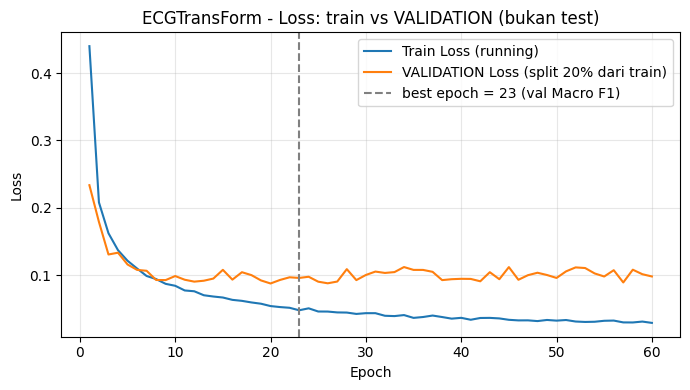

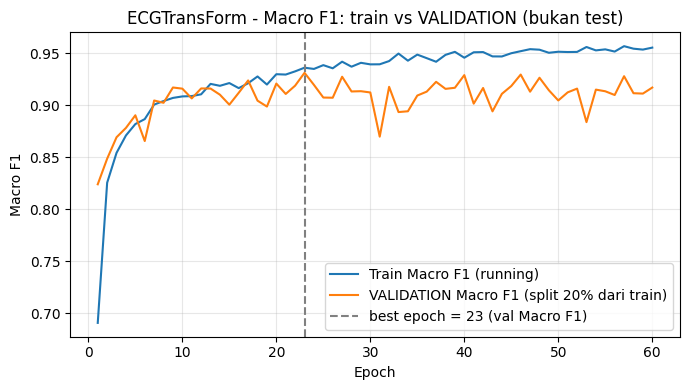

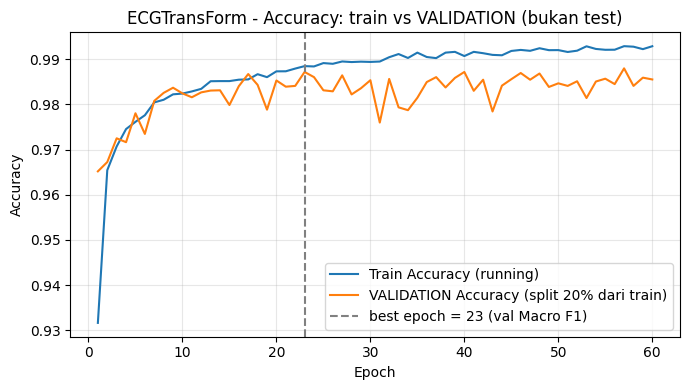

In [42]:
# ===== 9. Kurva training (train vs VALIDATION; bukan test) =====
if os.path.exists(HISTORY_CSV):
    H = pd.read_csv(HISTORY_CSV)
    best_ep = json.load(open(BEST_JSON))["best_epoch"] if os.path.exists(BEST_JSON) else None
    specs = [("loss", "train_loss", "val_loss", "Loss", "ecgtransform_loss_curve.png"),
             ("macro_f1", "train_macro_f1", "val_macro_f1", "Macro F1", "ecgtransform_macro_f1_curve.png"),
             ("accuracy", "train_accuracy", "val_accuracy", "Accuracy", "ecgtransform_accuracy_curve.png")]
    for _, tcol, vcol, label, fname in specs:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(H["epoch"], H[tcol], label=f"Train {label} (running)")
        ax.plot(H["epoch"], H[vcol], label=f"VALIDATION {label} (split 20% dari train)")
        if best_ep:
            ax.axvline(best_ep, ls="--", c="gray", label=f"best epoch = {best_ep} (val Macro F1)")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label)
        ax.set_title(f"ECGTransForm - {label}: train vs VALIDATION (bukan test)")
        ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
        fig.savefig(os.path.join(FIG_DIR, fname), dpi=150); plt.show()
else:
    print("Belum ada history training -> plot dilewati.")

/content/ECGTransForm/models.py:41: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=3)


Memuat best checkpoint: epoch 23 (dipilih dari validation Macro F1 0.9314)


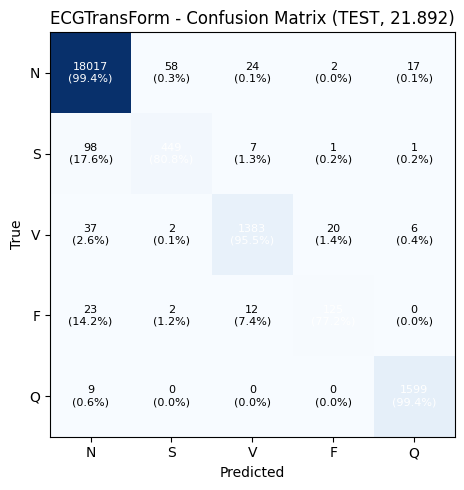

,precision,recall,f1-score,support
N,0.9908,0.9944,0.9926,18118.0000
S,0.8787,0.8076,0.8416,556.0000
V,0.9698,0.9551,0.9624,1448.0000
F,0.8446,0.7716,0.8065,162.0000
Q,0.9852,0.9944,0.9898,1608.0000
accuracy,0.9854,0.9854,0.9854,0.9854
macro avg,0.9338,0.9046,0.9186,21892.0000
weighted avg,0.9851,0.9854,0.9852,21892.0000


,pred_N,pred_S,pred_V,pred_F,pred_Q
true_N,18017,58,24,2,17
true_S,98,449,7,1,1
true_V,37,2,1383,20,6
true_F,23,2,12,125,0
true_Q,9,0,0,0,1599



Evaluasi test selesai (satu kali).


In [43]:
# ===== 10. EVALUASI TEST AKHIR (SATU kali, checkpoint terbaik berdasarkan VALIDATION Macro F1) =====
if RUN_FINAL_EVALUATION:
    if os.path.exists(TEST_METRICS_CSV):
        print("Evaluasi test SUDAH pernah dijalankan (file hasil ada). Tidak dijalankan ulang agar test set hanya dievaluasi satu kali.")
        print("Hasil tersimpan dapat dilihat di sel ringkasan terakhir.")
    else:
        H = pd.read_csv(HISTORY_CSV) if os.path.exists(HISTORY_CSV) else pd.DataFrame()
        assert os.path.exists(BEST_JSON) and os.path.exists(BEST_CKPT), "Best checkpoint belum ada: jalankan training dulu."
        assert len(H) == NUM_EPOCHS, f"Training belum selesai ({len(H)}/{NUM_EPOCHS} epoch). Lanjutkan (RESUME=True) sebelum evaluasi test."
        bj = json.load(open(BEST_JSON))
        # integritas test: file tidak berubah sejak awal sesi
        assert sha256_file(TRAIN_FILES["X_test.npy"]) == TEST_SHA_BEFORE["X"] and sha256_file(TRAIN_FILES["y_test.npy"]) == TEST_SHA_BEFORE["y"], "File test berubah!"
        assert len(X_test) == 21892 and len(y_test) == 21892

        set_seed(SEED)
        final_model = build_model()
        ck = load_ckpt(BEST_CKPT, final_model, None, restore_random=False)
        assert ck["epoch"] == bj["best_epoch"], "Epoch di best checkpoint != best_checkpoint.json"
        print(f"Memuat best checkpoint: epoch {ck['epoch']} (dipilih dari validation Macro F1 {bj['best_val_macro_f1']:.4f})")

        test_ds = Load_Dataset(to_ecgtransform_dict(X_test, y_test))   # <- SATU-SATUNYA tempat test dibuat DataLoader
        test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=0)
        assert len(test_ds) == 21892
        tm, yt, yp = evaluate(final_model, test_loader, return_preds=True)
        assert len(yt) == 21892 and np.array_equal(yt, y_test.astype(np.int64))

        rep = classification_report(yt, yp, labels=list(range(N_CLASSES)), target_names=CLASS_NAMES, digits=4, zero_division=0, output_dict=True)
        rep_df = pd.DataFrame(rep).T; rep_df.to_csv(TEST_REPORT_CSV)
        cm = confusion_matrix(yt, yp, labels=list(range(N_CLASSES)))
        cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in CLASS_NAMES], columns=[f"pred_{c}" for c in CLASS_NAMES]); cm_df.to_csv(TEST_CM_CSV)
        per_class_recall = {c: float(rep[c]["recall"]) for c in CLASS_NAMES}

        row = {"split": "TEST", "n_samples": int(len(yt)), "best_epoch": bj["best_epoch"],
               "accuracy_pct": tm["accuracy"] * 100, "macro_precision_pct": tm["macro_precision"] * 100,
               "macro_recall_pct": tm["macro_recall"] * 100, "macro_f1_pct": tm["macro_f1"] * 100, "loss_cal_weighted": tm["loss"]}
        row.update({f"recall_{c}_pct": v * 100 for c, v in per_class_recall.items()})
        pd.DataFrame([row]).to_csv(TEST_METRICS_CSV, index=False)

        fig, ax = plt.subplots(figsize=(6, 5))
        ax.imshow(cm, cmap="Blues")
        rown = cm / cm.sum(1, keepdims=True).clip(min=1)
        for i in range(N_CLASSES):
            for j in range(N_CLASSES):
                ax.text(j, i, f"{cm[i, j]}\n({rown[i, j] * 100:.1f}%)", ha="center", va="center", fontsize=8,
                        color="white" if rown[i, j] > .5 else "black")
        ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("ECGTransForm - Confusion Matrix (TEST, 21.892)")
        fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "ecgtransform_confusion_matrix.png"), dpi=150); plt.show()

        assert sha256_file(TRAIN_FILES["X_test.npy"]) == TEST_SHA_BEFORE["X"], "File test berubah selama evaluasi!"
        display(rep_df.round(4)); display(cm_df)
        log_update(final_test_metrics={"accuracy": tm["accuracy"], "macro_precision": tm["macro_precision"], "macro_recall": tm["macro_recall"],
                                       "macro_f1": tm["macro_f1"], "per_class_recall": per_class_recall},
                   status="EVALUATED", test_evaluated_once_at=datetime.now().isoformat(timespec="seconds"),
                   test_integrity="file test identik sebelum/sesudah")
        print("\nEvaluasi test selesai (satu kali).")
else:
    print("RUN_FINAL_EVALUATION = False -> test set tidak disentuh.")

In [44]:
# ===== 11. RINGKASAN AKHIR (dibaca dari file tersimpan; aman dijalankan kapan saja) =====
def _fmt(v):
    return f"{v:.2f}%"


print("ECGTRANSFORM TRAINING SUMMARY")
print("=" * 32)
if not os.path.exists(BEST_JSON):
    print("\nTRAINING BELUM DIJALANKAN / belum ada checkpoint terbaik.")
    print("FINAL DECISION: BELUM ADA HASIL (full training: NOT RUN YET)")
else:
    bj = json.load(open(BEST_JSON))
    print(f"\nBest Epoch:           {bj['best_epoch']}")
    print(f"Validation Macro F1:  {bj['best_val_macro_f1'] * 100:.2f}%")
    print(f"Validation Accuracy:  {bj['best_val_accuracy'] * 100:.2f}%")
    if not os.path.exists(TEST_METRICS_CSV):
        print("\nTEST RESULTS: BELUM DIEVALUASI (setel RUN_FINAL_EVALUATION = True setelah training selesai).")
        print("FINAL DECISION: BELUM ADA HASIL TEST")
    else:
        T = pd.read_csv(TEST_METRICS_CSV).iloc[0]
        mine = {"accuracy": float(T["accuracy_pct"]), "macro_precision": float(T["macro_precision_pct"]),
                "macro_recall": float(T["macro_recall_pct"]), "macro_f1": float(T["macro_f1_pct"])}
        diff = {k: mine[k] - BASELINE[k] for k in BASELINE}
        improved = {k: d > 0 for k, d in diff.items()}
        decision = "SUPERIOR ON AT LEAST ONE METRIC" if any(improved.values()) else "DOES NOT EXCEED BASELINE"
        names = {"accuracy": "Accuracy", "macro_precision": "Macro Precision", "macro_recall": "Macro Recall", "macro_f1": "Macro F1"}

        print("\nTEST RESULTS (hasil eksperimen notebook ini; 21.892 sampel, evaluasi satu kali)")
        print("-" * 12)
        for k in BASELINE: print(f"{names[k] + ':':<18}{_fmt(mine[k])}")
        print("\nBASELINE (ResNet18 + GAF, Week 1)")
        print("-" * 8)
        for k in BASELINE: print(f"{names[k] + ':':<18}{_fmt(BASELINE[k])}")
        print("\nDIFFERENCE (ECGTransForm - ResNet18 + GAF, percentage points)")
        print("-" * 10)
        for k in BASELINE: print(f"{names[k] + ':':<18}{diff[k]:+.2f} pp  ->  {'improvement' if improved[k] else 'no improvement'}")
        print("\nFINAL DECISION")
        print("-" * 14)
        print(decision)

        comp = pd.DataFrame([{"Model": "ResNet18 + GAF", **{names[k]: BASELINE[k] for k in BASELINE}},
                             {"Model": "ECGTransForm", **{names[k]: mine[k] for k in BASELINE}},
                             {"Model": "Difference (pp)", **{names[k]: diff[k] for k in BASELINE}}])
        comp.to_csv(COMPARISON_CSV, index=False); display(comp.round(2))
        print("\nCatatan metodologis:")
        print(" - Satu seed, satu run: selisih kecil bisa berada dalam variasi antar-seed (tidak ada uji signifikansi).")
        print(" - Baseline Week 1 memilih checkpoint berdasarkan test set (cenderung optimistis); ECGTransForm dipilih dari validation -> perbandingan ini konservatif untuk ECGTransForm.")
        print(" - Angka dari paper TIDAK dipakai di sini; hanya hasil run notebook ini.")
        log_update(final_decision=decision, comparison_vs_baseline={"baseline": BASELINE, "ecgtransform": mine, "difference_pp": diff},
                   status="COMPLETED",
                   notes=[
                       "Loop training di notebook mereplikasi Adam(betas 0.9/0.99, lr 1e-3, wd 1e-4) + CrossEntropyLoss(weight=CAL) dari trainer.py; di-guard terhadap scheduler/clip/warmup/AMP.",
                       "Beda dari repo: checkpoint dipilih dari best validation Macro F1 dan test dievaluasi pada checkpoint itu (repo: test pada epoch terakhir).",
                       "Beda dari repo: validation loader drop_last=False; DataLoader memakai Load_Dataset repo, bukan data_generator (agar tidak butuh file .pt & agar val lengkap).",
                       "Paper menyebut dropout 0.5, config repo 0.2 -> memakai repo (0.2). sequence_len=186 di config tidak dipakai kode; input 187 titik utuh.",
                       "Train mentah: lihat train_source_status di log ini. Bukan reproduksi exact paper; ada adaptasi data format (reshape/cast), split validasi, resume.",
                       "Metrik train = metrik berjalan selama epoch (dropout aktif).",
                   ])
        print(f"\nExperiment log: {EXP_LOG_PATH}")

ECGTRANSFORM TRAINING SUMMARY

Best Epoch:           23
Validation Macro F1:  93.14%
Validation Accuracy:  98.72%

TEST RESULTS (hasil eksperimen notebook ini; 21.892 sampel, evaluasi satu kali)
------------
Accuracy:         98.54%
Macro Precision:  93.38%
Macro Recall:     90.46%
Macro F1:         91.86%

BASELINE (ResNet18 + GAF, Week 1)
--------
Accuracy:         98.86%
Macro Precision:  95.23%
Macro Recall:     91.97%
Macro F1:         93.53%

DIFFERENCE (ECGTransForm - ResNet18 + GAF, percentage points)
----------
Accuracy:         -0.32 pp  ->  no improvement
Macro Precision:  -1.85 pp  ->  no improvement
Macro Recall:     -1.51 pp  ->  no improvement
Macro F1:         -1.67 pp  ->  no improvement

FINAL DECISION
--------------
DOES NOT EXCEED BASELINE


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet18 + GAF,98.86,95.23,91.97,93.53
1,ECGTransForm,98.54,93.38,90.46,91.86
2,Difference (pp),-0.32,-1.85,-1.51,-1.67



Catatan metodologis:
 - Satu seed, satu run: selisih kecil bisa berada dalam variasi antar-seed (tidak ada uji signifikansi).
 - Baseline Week 1 memilih checkpoint berdasarkan test set (cenderung optimistis); ECGTransForm dipilih dari validation -> perbandingan ini konservatif untuk ECGTransForm.
 - Angka dari paper TIDAK dipakai di sini; hanya hasil run notebook ini.

Experiment log: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/ecgtransform_experiment_log.json
